# Task 1: Basic Data Cleaning and Exploration

## Introduction
This notebook uses the supplied e-commerce order-item dataset. The goal is to check its quality, make careful and documented cleaning choices, and explore its basic structure without removing unusual but potentially genuine transactions.

## Why clean and explore the data?
Cleaning makes missing and inconsistent values easier to understand, while basic exploration shows the shape, types, and distributions in the data. These checks are important before using the dataset for further analysis. I will keep the original records available for comparison and will not assume that an extreme value is an error.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## Load the dataset
The original CSV is stored in the project's `Dataset` folder. This relative path works when Jupyter is started from the `Task_1` folder, as shown in the README. I keep an untouched copy in `original_df` so the source and cleaned data can be compared later.


In [2]:
original_df = pd.read_csv("../Dataset/Original_Dataset.csv", low_memory=False)
df = original_df.copy()

print("Dataset loaded successfully.")
print("Original shape:", original_df.shape)


Dataset loaded successfully.
Original shape: (584524, 21)


## Preview the records
Looking at the beginning and end of the file helps confirm that the CSV was read correctly and gives a first look at its records.

In [3]:
display(df.head())

,item_id,status,created_at,sku,price,qty_ordered,grand_total,increment_id,category_name_1,sales_commission_code,discount_amount,payment_method,Working Date,BI Status,MV,Year,Month,Customer Since,M-Y,FY,Customer ID
0,211131,complete,07/01/2016,kreations_YI 06-L,1950.0,1,1950.0,100147443,Women's Fashion,Not provided,0.0,cod,07/01/2016,#REF!,"1,950",2016,7,2016-7,Jul-16,FY17,1.0
1,211133,canceled,07/01/2016,kcc_Buy 2 Frey Air Freshener & Get 1 Kasual Bo...,240.0,1,240.0,100147444,Beauty & Grooming,Not provided,0.0,cod,07/01/2016,Gross,240,2016,7,2016-7,Jul-16,FY17,2.0
2,211134,canceled,07/01/2016,Ego_UP0017-999-MR0,2450.0,1,2450.0,100147445,Women's Fashion,Not provided,0.0,cod,07/01/2016,Gross,"2,450",2016,7,2016-7,Jul-16,FY17,3.0
3,211135,complete,07/01/2016,kcc_krone deal,360.0,1,60.0,100147446,Beauty & Grooming,R-FSD-52352,300.0,cod,07/01/2016,Net,360,2016,7,2016-7,Jul-16,FY17,4.0
4,211136,order_refunded,07/01/2016,BK7010400AG,555.0,2,1110.0,100147447,Soghaat,Not provided,0.0,cod,07/01/2016,Valid,"1,110",2016,7,2016-7,Jul-16,FY17,5.0


In [4]:
display(df.tail())

,item_id,status,created_at,sku,price,qty_ordered,grand_total,increment_id,category_name_1,sales_commission_code,discount_amount,payment_method,Working Date,BI Status,MV,Year,Month,Customer Since,M-Y,FY,Customer ID
584519,905204,cod,8/28/2018,WOFSCE5AE00357AECDE,699.0,1,849.0,100562385,Women's Fashion,Not provided,0.0,cod,8/28/2018,Valid,699,2018,8,2018-8,Aug-18,FY19,115320.0
584520,905205,processing,8/28/2018,MATHUA5AF70A7D1E50A,35599.0,1,35899.0,100562386,Mobiles & Tablets,Not provided,0.0,bankalfalah,8/28/2018,Gross,"35,599",2018,8,2018-8,Aug-18,FY19,115326.0
584521,905206,processing,8/28/2018,MATSAM5B6D7208C6D30,129999.0,2,652178.0,100562387,Mobiles & Tablets,Not provided,0.0,bankalfalah,8/28/2018,Gross,"259,998",2018,8,2018-7,Aug-18,FY19,113474.0
584522,905207,processing,8/28/2018,MATSAM5B1509B4696EA,87300.0,2,652178.0,100562387,Mobiles & Tablets,Not provided,0.0,bankalfalah,8/28/2018,Gross,"174,600",2018,8,2018-7,Aug-18,FY19,113474.0
584523,905208,processing,8/28/2018,MATSAM5B10F91A9B6AB,108640.0,2,652178.0,100562387,Mobiles & Tablets,Not provided,0.0,bankalfalah,8/28/2018,Gross,"217,280",2018,8,2018-7,Aug-18,FY19,113474.0


The preview shows order-item records with fields such as status, item price, quantity, category, payment method, and date. The data contains many more records than can be inspected manually, so the following summaries are useful.

## Dataset shape, columns, and data types
The shape tells us how many records and fields are available. Column names and data types help identify which fields are numeric, text, or dates stored as text.

In [5]:
print("Rows and columns:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nData types:")
print(df.dtypes)

Rows and columns: (584524, 21)

Column names:
['item_id', 'status', 'created_at', 'sku', 'price', 'qty_ordered', 'grand_total', 'increment_id', 'category_name_1', 'sales_commission_code', 'discount_amount', 'payment_method', 'Working Date', 'BI Status', 'MV', 'Year', 'Month', 'Customer Since', 'M-Y', 'FY', 'Customer ID']

Data types:
item_id                    int64
status                       str
created_at                   str
sku                          str
price                    float64
qty_ordered                int64
grand_total              float64
increment_id                 str
category_name_1              str
sales_commission_code        str
discount_amount          float64
payment_method               str
Working Date                 str
BI Status                    str
MV                           str
Year                       int64
Month                      int64
Customer Since               str
M-Y                          str
FY                           str
Cust

## General information and numeric summary
`info()` shows the non-null counts and data types. `describe()` gives a first numerical summary; very large ranges may indicate outliers that should be reviewed, not automatically deleted.

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 584524 entries, 0 to 584523
Data columns (total 21 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   item_id                584524 non-null  int64  
 1   status                 584524 non-null  str    
 2   created_at             584524 non-null  str    
 3   sku                    584524 non-null  str    
 4   price                  584524 non-null  float64
 5   qty_ordered            584524 non-null  int64  
 6   grand_total            584524 non-null  float64
 7   increment_id           584524 non-null  str    
 8   category_name_1        584524 non-null  str    
 9   sales_commission_code  584524 non-null  str    
 10  discount_amount        584524 non-null  float64
 11  payment_method         584524 non-null  str    
 12  Working Date           584524 non-null  str    
 13  BI Status              584524 non-null  str    
 14  MV                     584524 non-null  str    

In [7]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
item_id,584524.0,565667.074218,200121.173648,211131.0,395000.75,568424.5,739106.25,905208.0
price,584524.0,6348.747531,14949.269515,0.0,360.00,899.0,4070.00,1012625.9
qty_ordered,584524.0,1.296388,3.996061,1.0,1.00,1.0,1.00,1000.0
grand_total,584524.0,8530.618571,61320.814625,-1594.0,945.00,1960.4,6999.00,17888000.0
discount_amount,584524.0,499.492775,1506.943046,-599.5,0.00,0.0,160.50,90300.0
Year,584524.0,2017.044115,0.707355,2016.0,2017.00,2017.0,2018.00,2018.0
Month,584524.0,7.167654,3.486305,1.0,4.00,7.0,11.00,12.0
Customer ID,584513.0,45790.511965,34414.962389,1.0,13516.00,42856.0,73536.00,115326.0


## Identify missing values and placeholders
Some files use text to represent missing or broken values. In this dataset, `Not provided` is used for an unavailable commission code and `#REF!` appears once in the BI Status field. I first count these separately from values that Pandas already recognizes as missing.

In [8]:
placeholder_map = {
    "sales_commission_code": "Not provided",
    "BI Status": "#REF!"
}

placeholder_counts = pd.Series(0, index=df.columns, dtype="int64")
for column, placeholder in placeholder_map.items():
    placeholder_counts[column] = original_df[column].eq(placeholder).sum()

missing_check = pd.DataFrame({
    "native_missing": original_df.isna().sum(),
    "placeholder_values": placeholder_counts
})
missing_check = missing_check.loc[missing_check.gt(0).any(axis=1)]
missing_check["native_missing_percent"] = (
    missing_check["native_missing"] / len(original_df) * 100
).round(3)
display(missing_check)

,native_missing,placeholder_values,native_missing_percent
sales_commission_code,0,476179,0.000
BI Status,0,1,0.000
Customer ID,11,0,0.002


## Standardize missing values and calculate percentages
I convert the two known placeholders to `NaN` so they are counted consistently. I will not fill these values with guesses: commission codes and customer IDs are identifiers, and the BI error does not tell us the correct status.

In [9]:
for column, placeholder in placeholder_map.items():
    df[column] = df[column].replace(placeholder, np.nan)

missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(3)
})
missing_summary = missing_summary[missing_summary["missing_count"] > 0]
display(missing_summary)

,missing_count,missing_percent
sales_commission_code,476179,81.464
BI Status,1,0.000
Customer ID,11,0.002


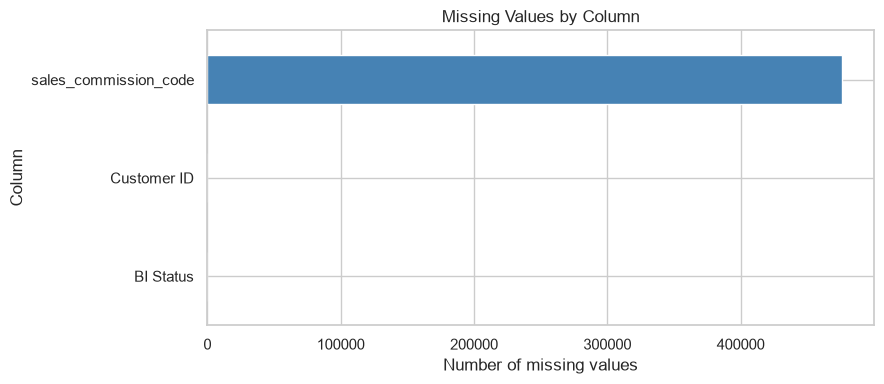

In [10]:
missing_counts = df.isna().sum()
missing_counts = missing_counts[missing_counts > 0].sort_values()

plt.figure(figsize=(9, 4))
missing_counts.plot(kind="barh", color="steelblue")
plt.title("Missing Values by Column")
plt.xlabel("Number of missing values")
plt.ylabel("Column")
plt.tight_layout()
plt.show()

After standardizing the placeholders, missing values are limited to the commission-code field, the BI Status field, and 11 customer IDs. The commission code is unavailable for many rows, so filling it with a made-up code would be misleading. The missing customer IDs are also left blank because they cannot be reliably inferred.

## Identify and remove exact duplicate records
I check for rows that are identical across every column and remove only those exact duplicates. Multiple rows with the same order number can be separate items in one order, so an order number by itself is not treated as a duplicate.

In [11]:
duplicates_before = df.duplicated().sum()
df = df.drop_duplicates().copy()

print("Exact duplicate rows found:", duplicates_before)
print("Shape after removing exact duplicates:", df.shape)

Exact duplicate rows found: 0
Shape after removing exact duplicates: (584524, 21)


## Review outliers with the IQR method
For the main amount and quantity fields, I use the interquartile range (IQR) rule to flag values below Q1 - 1.5 x IQR or above Q3 + 1.5 x IQR. These flags are for review only. Large orders and expensive products may be genuine, so I keep all flagged records.

In [12]:
outlier_columns = ["price", "qty_ordered", "grand_total", "discount_amount"]
outlier_rows = []

for column in outlier_columns:
    q1 = df[column].quantile(0.25)
    q3 = df[column].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outlier_mask = (df[column] < lower_bound) | (df[column] > upper_bound)
    outlier_rows.append({
        "column": column,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "outlier_count": int(outlier_mask.sum()),
        "outlier_percent": round(outlier_mask.mean() * 100, 2)
    })

outlier_summary = pd.DataFrame(outlier_rows).set_index("column")
display(outlier_summary)

,lower_bound,upper_bound,outlier_count,outlier_percent
column,,,,
price,-5205.00,9635.00,105687,18.08
qty_ordered,1.00,1.00,79310,13.57
grand_total,-8136.00,16080.00,77090,13.19
discount_amount,-240.75,401.25,108986,18.65


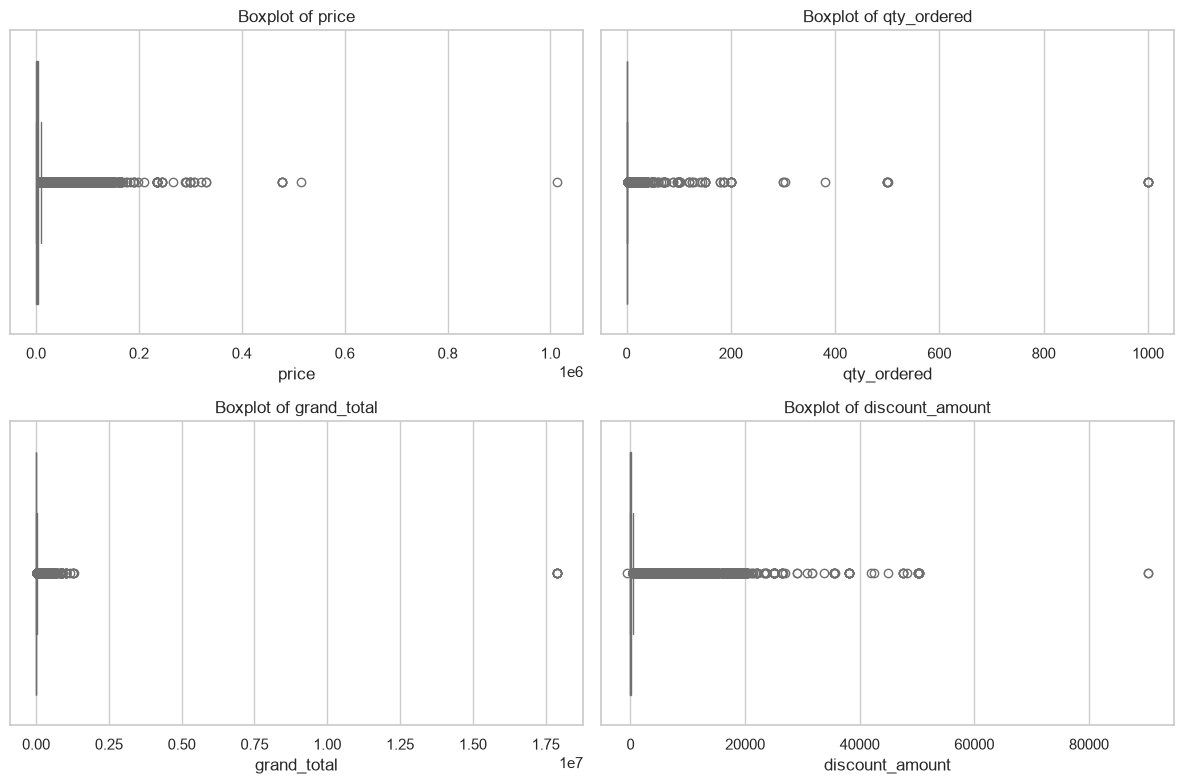

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for column, axis in zip(outlier_columns, axes.flatten()):
    sns.boxplot(x=df[column], ax=axis, color="skyblue")
    axis.set_title(f"Boxplot of {column}")
    axis.set_xlabel(column)

plt.tight_layout()
plt.show()

The boxplots show long upper tails in the amount and quantity fields. The IQR rule flags many records, which is a reason to investigate the transaction patterns rather than delete them automatically. No outlier rows were removed in this notebook.

## Basic statistics
The table below reports the mean, median, mode, minimum, maximum, and standard deviation for the main numeric transaction fields. The mean can be pulled upward by unusually large values, so it is useful to compare it with the median.

In [14]:
stat_columns = ["price", "qty_ordered", "grand_total", "discount_amount"]
statistics = pd.DataFrame(index=stat_columns)
statistics["mean"] = df[stat_columns].mean()
statistics["median"] = df[stat_columns].median()
statistics["mode"] = df[stat_columns].mode().iloc[0]
statistics["minimum"] = df[stat_columns].min()
statistics["maximum"] = df[stat_columns].max()
statistics["standard_deviation"] = df[stat_columns].std()
display(statistics.round(2))

,mean,median,mode,minimum,maximum,standard_deviation
price,6348.75,899.0,1000.0,0.0,1012625.9,14949.27
qty_ordered,1.30,1.0,1.0,1.0,1000.0,4.00
grand_total,8530.62,1960.4,0.0,-1594.0,17888000.0,61320.81
discount_amount,499.49,0.0,0.0,-599.5,90300.0,1506.94


For example, the median item price is much lower than its mean, showing that the price distribution is right-skewed. This is consistent with the high-price observations identified by the IQR check; the values are retained for further investigation.

## Histograms of numeric fields
Histograms show the overall shape of each distribution. A small number of very large values can make most observations appear close together, so these charts are used as a basic overview rather than as a reason to remove data.

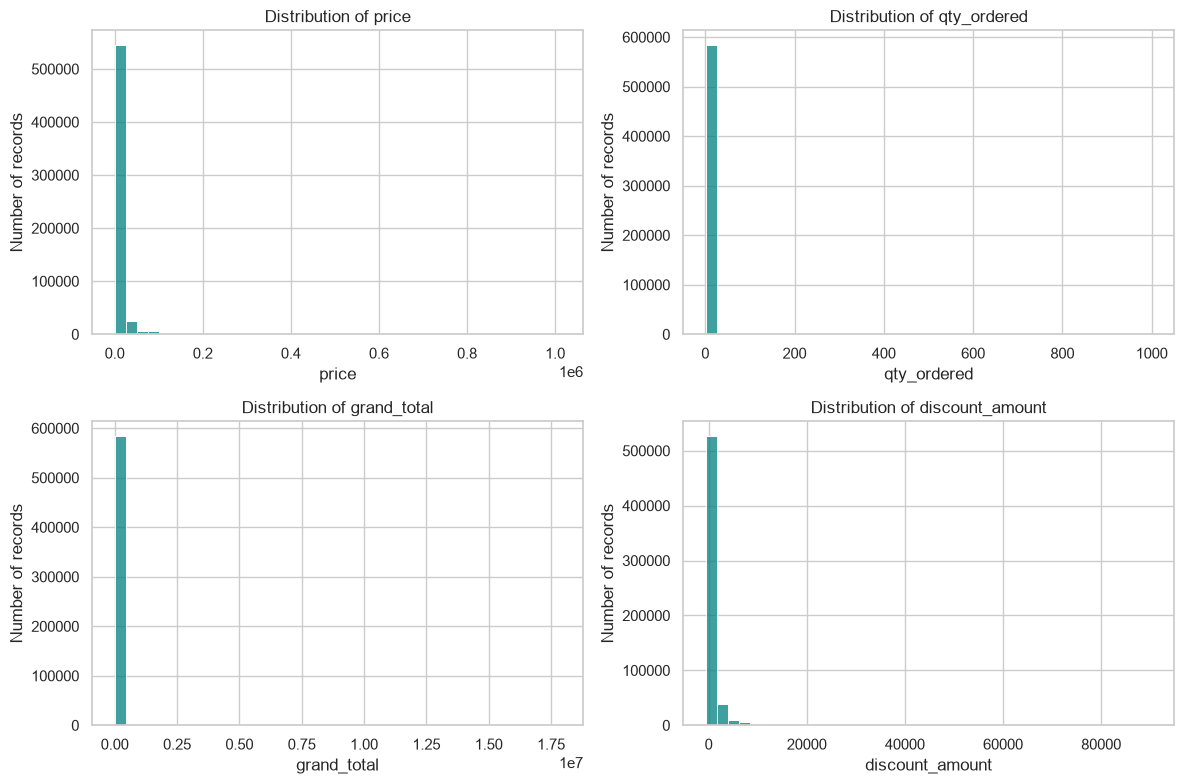

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for column, axis in zip(stat_columns, axes.flatten()):
    sns.histplot(data=df, x=column, bins=40, ax=axis, color="teal")
    axis.set_title(f"Distribution of {column}")
    axis.set_xlabel(column)
    axis.set_ylabel("Number of records")

plt.tight_layout()
plt.show()

The amount and price histograms are concentrated at lower values with long right tails. Quantity is also concentrated at one item per row. These distributions explain why the mean is higher than the median for several fields.

## Category-wise record counts
This basic bar chart counts order-item rows in the ten most common categories. It describes the dataset composition; it is not a sales comparison.

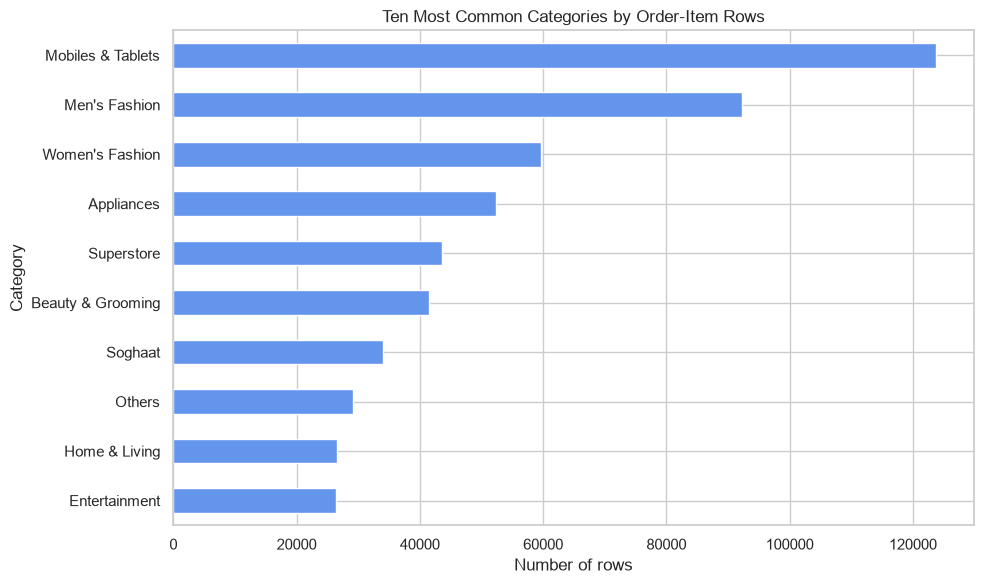

In [16]:
top_categories = df["category_name_1"].value_counts().head(10).sort_values()

plt.figure(figsize=(10, 6))
top_categories.plot(kind="barh", color="cornflowerblue")
plt.title("Ten Most Common Categories by Order-Item Rows")
plt.xlabel("Number of rows")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

Mobiles & Tablets has the most order-item rows in the dataset, followed by Men's Fashion. The counts show how often categories appear, not how much sales value they generated.

## Check the dataset after cleaning
I check the final shape, remaining missing values, and exact duplicates. Missing identifier and status information remains blank where it could not be recovered; those records are not discarded.

In [17]:
print("Cleaned shape:", df.shape)
print("Exact duplicate rows remaining:", df.duplicated().sum())
print("\nRemaining missing values:")
display(df.isna().sum()[df.isna().sum() > 0].to_frame("missing_count"))

Cleaned shape: (584524, 21)


Exact duplicate rows remaining: 0

Remaining missing values:


,missing_count
sales_commission_code,476179
BI Status,1
Customer ID,11


## Compare the original and cleaned dataset
The comparison distinguishes missing values present in the source file from text placeholders that were standardized to missing values. The row count only changes if exact duplicate records are found.

In [18]:
comparison = pd.DataFrame({
    "original": {
        "rows": len(original_df),
        "columns": original_df.shape[1],
        "native_missing_cells": int(original_df.isna().sum().sum()),
        "exact_duplicate_rows": int(original_df.duplicated().sum())
    },
    "cleaned": {
        "rows": len(df),
        "columns": df.shape[1],
        "native_missing_cells": int(df.isna().sum().sum()),
        "exact_duplicate_rows": int(df.duplicated().sum())
    }
})
display(comparison)

,original,cleaned
rows,584524,584524
columns,21,21
native_missing_cells,11,476191
exact_duplicate_rows,0,0


The cleaned data retains the original records because there are no exact duplicate rows to remove. The missing-cell count is higher after cleaning because known text placeholders are now represented consistently as missing values.

## Save the cleaned dataset
The cleaned CSV is saved as `Dataset/Cleaned_Dataset.csv`, beside the original source file. Task 2 reads this output directly, so the data-cleaning steps do not need to be repeated there.


In [19]:
df.to_csv("../Dataset/Cleaned_Dataset.csv", index=False)
print("Saved Dataset/Cleaned_Dataset.csv with shape:", df.shape)


Saved Dataset/Cleaned_Dataset.csv with shape: (584524, 21)


## Task 1 summary and conclusion

- **Cleaning performed:** standardized `Not provided` and `#REF!` placeholders as missing values, checked missing-value percentages, and checked and removed exact duplicate rows if present.
- **Problems found:** missing customer IDs and unavailable commission codes; one spreadsheet error in BI Status; strongly right-skewed numeric fields and many IQR outlier flags.
- **Improvements made:** missing-value representations are consistent, and the cleaned data is saved as `Cleaned_Dataset.csv` for reuse.
- **Data retained:** no exact duplicate rows were found, and IQR-flagged values were kept because they may be genuine transactions. Missing identifiers and status information were not guessed or imputed.

**Conclusion:** The dataset is ready for a separate business-focused EDA. Its unusual values and missing fields have been documented without discarding potentially valid order items.